In [234]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../../datos_completos.csv")
df_original = df.copy()

## 1. Inspección inicial del conjunto de datos

Comenzamos revisando las dimensiones del dataset, los tipos de datos y
la cantidad de valores disponibles en cada columna.

También mostramos las primeras y las últimas filas para comprobar
la estructura de los registros y observar cómo se representan
los textos, los indicadores, las fechas y los precios.

Con esta infomacíon podremos ver qué variables necesitan un tratamiento especial.

In [235]:
df.shape

(392, 30)

In [236]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 30 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   nregistro                      392 non-null    int64  
 1   nombre                         392 non-null    str    
 2   pactivos                       392 non-null    str    
 3   labtitular                     392 non-null    str    
 4   labcomercializador             392 non-null    str    
 5   cn                             392 non-null    int64  
 6   dosis                          392 non-null    str    
 7   formaFarmaceuticaSimplificada  392 non-null    str    
 8   estado_aut                     392 non-null    int64  
 9   estado_rev                     39 non-null     float64
 10  viasAdministracion             392 non-null    str    
 11  comerc                         392 non-null    bool   
 12  receta                         392 non-null    bool   
 13  g

In [237]:
df.head()

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,formaFarmaceuticaSimplificada,estado_aut,estado_rev,...,num_registros_atc,num_principios_activos,n_palabras,n_tablas,n_graves,estado_nomenclator,pvp_iva,precio_referencia,tratamiento_larga_duracion,especial_control_medico
0,52105,ACTOCORTINA 373 mg POLVO PARA SOLUCIÓN INYECTABLE,HIDROCORTISONA FOSFATO SODIO,Cheplapharm Arzneimittel Gmbh,Laboratorios Rubio S.A.,606558,373 MG,INYECTABLE,128905200000,NaN,...,3,1,1293,1,5,NaN,NaN,NaN,NaN,NaN
1,80248,AIRFLUSAL FORSPIRO 50 MICROGRAMOS/250 MICROGRA...,"FLUTICASONA PROPIONATO, SALMETEROL XINAFOATO",Sandoz Farmaceutica S.A.,Sandoz Farmaceutica S.A.,707896,50 microgramos/250 microgramos,INHALACIÓN PULMONAR,1447110000000,NaN,...,3,2,1543,5,16,ALTA,41.28,41.28,NO,NO
2,80249,AIRFLUSAL FORSPIRO 50 MICROGRAMOS/500 MICROGRA...,"SALMETEROL XINAFOATO, FLUTICASONA PROPIONATO",Sandoz Farmaceutica S.A.,Sandoz Farmaceutica S.A.,707904,50 microgramos/500 microgramos,INHALACIÓN PULMONAR,1447110000000,NaN,...,3,2,1543,5,16,ALTA,41.28,41.28,NO,NO
3,62839,ANASMA ACCUHALER 50 microgramos/100 microgramo...,"FLUTICASONA PROPIONATO, SALMETEROL XINAFOATO",Glaxosmithkline S.A.,Glaxosmithkline S.A.,842898,"0,1 mg / 0,05 mg",INHALACIÓN PULMONAR,945644400000,NaN,...,3,2,1435,7,20,ALTA,41.28,41.28,NO,NO
4,62840,ANASMA ACCUHALER 50 microgramos/250 microgramo...,"FLUTICASONA PROPIONATO, SALMETEROL XINAFOATO",Glaxosmithkline S.A.,Glaxosmithkline S.A.,700543,"0,25 mg / 0,05 mg",INHALACIÓN PULMONAR,945644400000,NaN,...,3,2,1436,7,20,ALTA,41.28,41.28,NO,NO


In [238]:
df.tail()

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,formaFarmaceuticaSimplificada,estado_aut,estado_rev,...,num_registros_atc,num_principios_activos,n_palabras,n_tablas,n_graves,estado_nomenclator,pvp_iva,precio_referencia,tratamiento_larga_duracion,especial_control_medico
387,66408,VENTILASTIN NOVOLIZER 100 microgramos/DOSIS PO...,SALBUTAMOL SULFATO,Mylan Ire Healthcare Limited,Mylan Pharmaceuticals S.L.,656705,100 mcg salbutamol sulfato,INHALACIÓN PULMONAR,1098741600000,1.703672e+12,...,3,1,725,1,10,NaN,NaN,NaN,NaN,NaN
388,52404,VENTOALDO 100 mcg/DOSIS SUSPENSION PARA INHALA...,SALBUTAMOL SULFATO,Laboratorio Aldo Union S.L.,Laboratorio Aldo Union S.L.,652530,"0,2400 g",INHALACIÓN PULMONAR,136591200000,NaN,...,3,1,561,0,11,ALTA,6.21,6.21,SI,NO
389,55497,VENTODUO 100 MICROGRAMOS/50 MICROGRAMOS/PULSAC...,"SALBUTAMOL SULFATO, BECLOMETASONA DIPROPIONATO",Laboratorio Aldo Union S.L.,Laboratorio Aldo Union S.L.,700656,50 microgramos/100 microgramos,INHALACIÓN PULMONAR,357516000000,NaN,...,3,2,1104,1,7,ALTA,9.59,NaN,NO,NO
390,53931,"VENTOLIN 4 mg, COMPRIMIDOS",SALBUTAMOL,Glaxosmithkline S.A.,Glaxosmithkline S.A.,845735,4 mg salbutamol,COMPRIMIDO,244508400000,1.699461e+12,...,3,1,678,0,8,BAJA GENERAL,2.81,2.81,SI,NO
391,5319002,XOLAIR 150 mg POLVO Y DISOLVENTE PARA SOLUCION...,OMALIZUMAB,Novartis Europharm Limited,Novartis Farmaceutica S.A.,652563,150 mg,INYECTABLE,1131577200000,NaN,...,3,1,755,9,24,NaN,NaN,NaN,NaN,NaN


El conjunto de datos contiene 392 registros y 30 columnas. Está compuesto por identificadores, información de los medicamentos, precios, metricas de las fichas técnicas y variables categóricas.

## 2. Estadísticas descriptivas de las variables 

Revisamos los estadísticos descriptivos de las variables para entender su distribución, identificar posibles valores atípicos y determinar si es necesario realizar transformaciones o normalizaciones.




In [239]:
df.describe()

,nregistro,cn,estado_aut,estado_rev,num_registros_atc,num_principios_activos,n_palabras,n_tablas,n_graves,pvp_iva,precio_referencia
count,3.920000e+02,392.000000,3.920000e+02,3.900000e+01,392.0,392.000000,392.000000,392.000000,392.000000,307.000000,276.000000
mean,1.125497e+08,722732.022959,1.149884e+12,1.718959e+12,3.0,1.278061,961.094388,3.022959,10.584184,22.258534,19.751630
std,3.464286e+08,76855.626559,4.989010e+11,3.995249e+10,0.0,0.476269,505.741408,4.887165,11.682415,23.329557,13.830482
min,1.891000e+03,600447.000000,-1.512086e+12,1.635258e+12,3.0,1.000000,13.000000,0.000000,0.000000,1.200000,1.200000
25%,6.284375e+04,670509.000000,9.466164e+11,1.701942e+12,3.0,1.000000,402.000000,1.000000,4.000000,6.385000,6.195000
50%,7.293150e+04,705032.000000,1.290553e+12,1.721738e+12,3.0,1.000000,946.000000,2.000000,8.000000,21.060000,21.060000
75%,8.377275e+04,731103.250000,1.485458e+12,1.754131e+12,3.0,2.000000,1398.000000,4.000000,14.000000,39.405000,31.387500
max,1.252007e+09,995233.000000,1.778589e+12,1.781170e+12,3.0,3.000000,2715.000000,61.000000,106.000000,320.740000,41.960000


## 3. Revisión de duplicados y diversidad de valores

Comprobamos si existen filas duplicadas en el dataset y analizamos la diversidad de valores en cada columna para identificar posibles problemas de calidad de datos o la necesidad de realizar un preprocesamiento adicional.


In [240]:
df.duplicated().sum()

np.int64(0)

Vemos que hay 0 filas duplicadas, por lo que no es necesario realizar ninguna acción al respecto.

Revisamos también el número de valores únicos en cada columna

In [241]:
df.nunique()

nregistro                        392
nombre                           392
pactivos                          56
labtitular                        79
labcomercializador                69
cn                               392
dosis                            210
formaFarmaceuticaSimplificada     11
estado_aut                       271
estado_rev                        38
viasAdministracion                 9
comerc                             2
receta                             1
generico                           2
conduc                             2
triangulo                          2
huerfano                           1
biosimilar                         2
url_html_ficha_tecnica           392
url_foto_materiales              167
num_registros_atc                  1
num_principios_activos             3
n_palabras                       215
n_tablas                          15
n_graves                          34
estado_nomenclator                 4
pvp_iva                           84
p

In [242]:
df.isna().sum()

nregistro                          0
nombre                             0
pactivos                           0
labtitular                         0
labcomercializador                 0
cn                                 0
dosis                              0
formaFarmaceuticaSimplificada      0
estado_aut                         0
estado_rev                       353
viasAdministracion                 0
comerc                             0
receta                             0
generico                           0
conduc                             0
triangulo                          0
huerfano                           0
biosimilar                         0
url_html_ficha_tecnica             0
url_foto_materiales              225
num_registros_atc                  0
num_principios_activos             0
n_palabras                         0
n_tablas                           0
n_graves                           0
estado_nomenclator                85
pvp_iva                           85
p

Hay varias columnas con muchísimos valores nulos, por lo que las trataremos de distinta forma. También hay algunas columnas que tienen un único valor, por lo que no aportan información y también las eliminaremos.

## 4. Clasificación de las columnas

Vamos ahora a revisar los valores que tiene cada columna, para clasificarlas como categoricas o numéricas y para identificar las que no aportan información

In [243]:
for column in df.columns:
    print(df[column].value_counts())

nregistro
52105         1
80248         1
80249         1
62839         1
62840         1
62841         1
63924         1
63925         1
63923         1
65226         1
65236         1
52810         1
59522         1
59523         1
1201441006    1
1201441010    1
1201441002    1
59675         1
59676         1
89439         1
89440         1
67037         1
66943         1
66942         1
83987         1
61664         1
61663         1
73873         1
73872         1
64926         1
64918         1
66990         1
66989         1
1252007001    1
1171252001    1
1171252002    1
60480         1
60482         1
60479         1
60477         1
60528         1
60530         1
60527         1
60525         1
78536         1
78537         1
78538         1
62197         1
76740         1
80708         1
68809         1
80600         1
66573         1
76713         1
80707         1
68802         1
80599         1
78813         1
78803         1
90505         1
60689         1
60691         

In [244]:
numerical_columns = ["precio_referencia", "pvp_iva", "n_graves", "n_tablas", "n_palabras", "num_principios_activos"]
categorical_columns = ["formaFarmaceuticaSimplificada", "tratamiento_larga_duracion", "estado_nomenclator", "biosimilar", "triangulo", "conduc", "generico", "comerc", "viasAdministracion"] 
drop_columns =["nregistro", "nombre", "cn", "url_foto_materiales", "url_html_ficha_tecnica", "estado_rev", "estado_aut", "labtitular", "pactivos", "num_registros_atc", "especial_control_medico", "huerfano", "receta", "dosis"]

Hemos puesto en drop_columns las columnas que tienen muchisimos nulos, las que no aportan informacion (como el nombre del medicamento, el cn o las urls) y las que solo tienen una categoria ( "num_registros_atc", "especial_control_medico", "huerfano", "receta"). La columna dosis contiene valores como "50 ml", "2 microgramos", "3 mg", "4 ug", contiene concentraciones... Debido a la gran variedad de unidades y formatos, no es posible normalizarla y por lo tanto no aporta información para el modelo. Por ello, la eliminamos también.

## 5. Distribución de las variables numericas

Representamos las variables numéricas para observar dónde se concentran
los valores, su dispersión y la presencia de posibles valores extremos.

Los histogramas se calculan con los datos disponibles, antes de imputar
los valores ausentes.


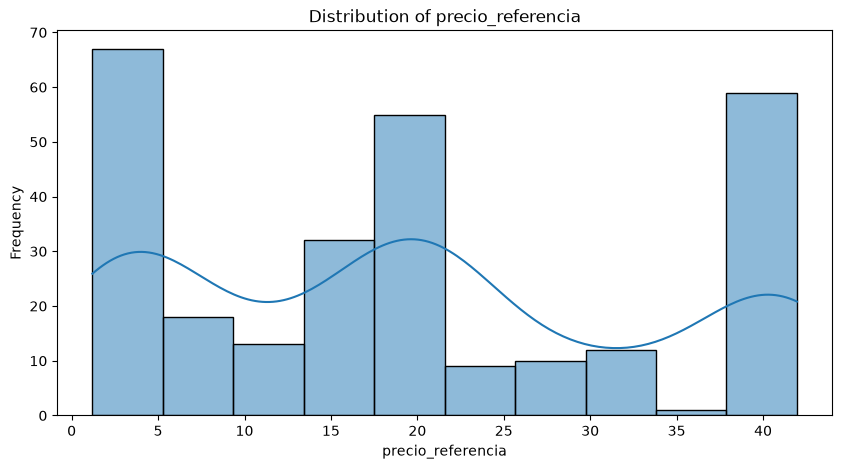

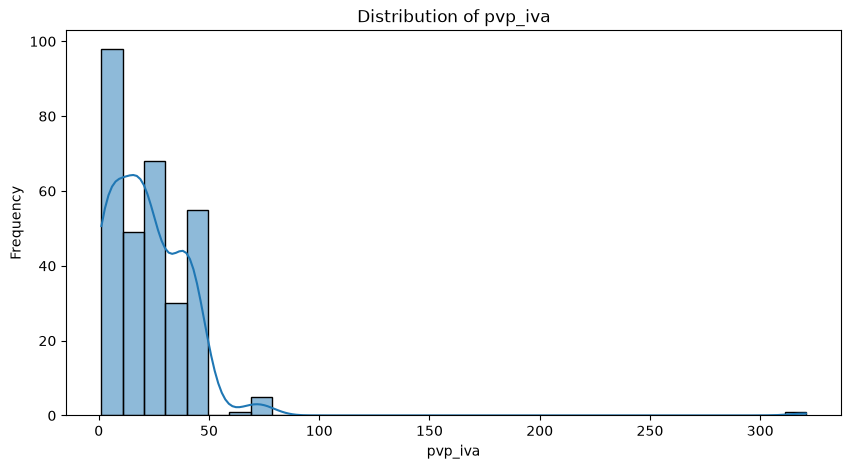

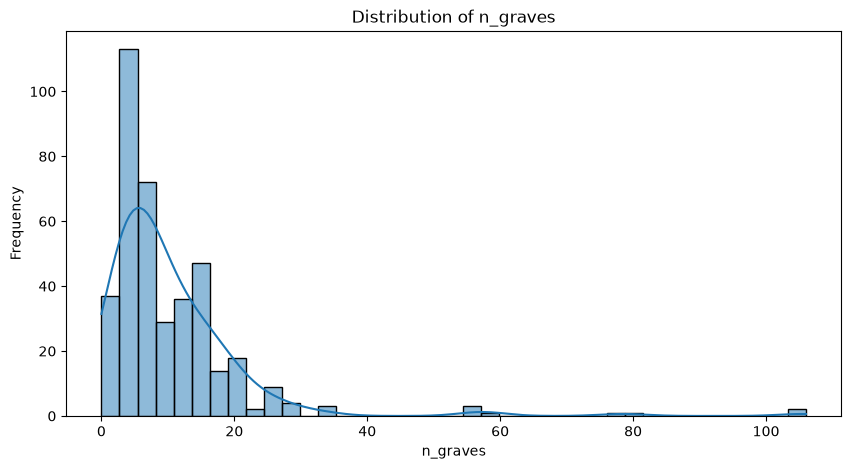

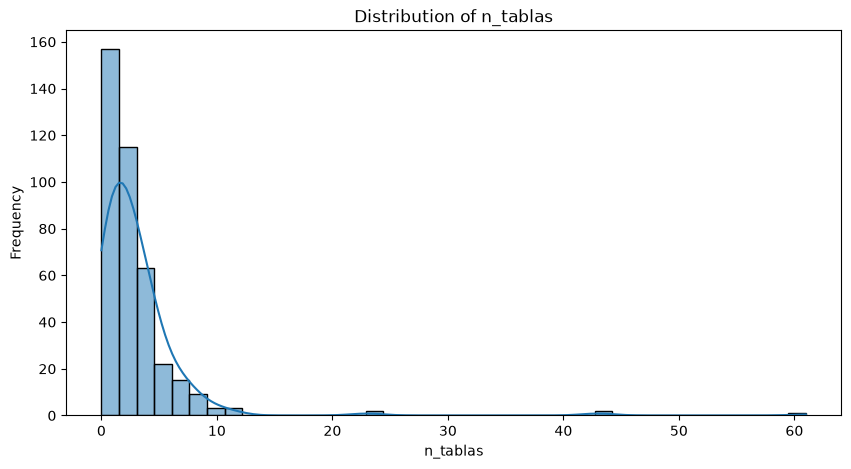

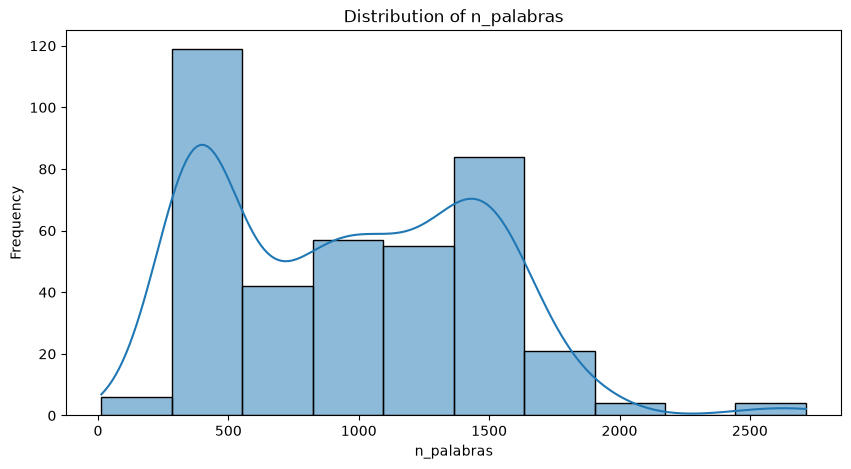

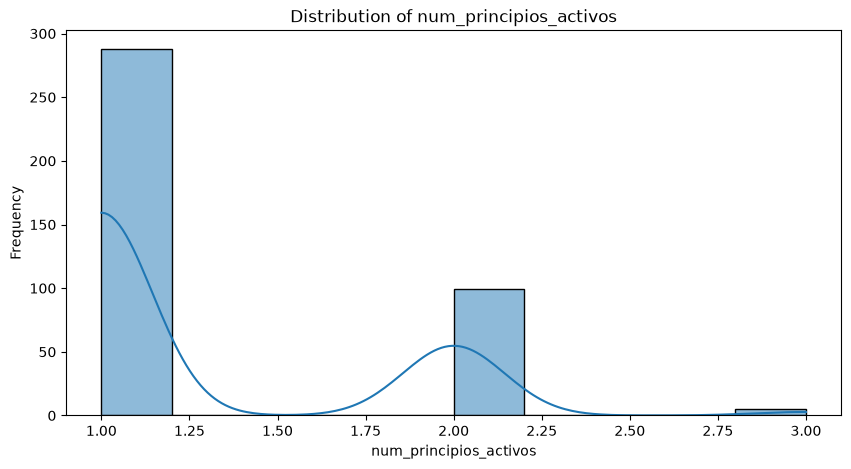

In [245]:
for column in numerical_columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[column], kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

Los precios se concentran en los valores bajos y medios, aunque destaca
un PVP de más de 300 que revisaremos individualmente.
Los recuentos de tablas y de graves presentan algunos valores elevados, pero que no son necesariamente erróneos, ya que se trata de recuentos de la ficha técnica.
La extensión de los textos es variable, con mucha cantidad entre 500 y 1500 palabras.
Predominan los medicamentos con un único principio activo, y también destacan que hay muy pocos con 3 principios activos.


In [246]:
df[df["pvp_iva"] > 300]

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,formaFarmaceuticaSimplificada,estado_aut,estado_rev,...,num_registros_atc,num_principios_activos,n_palabras,n_tablas,n_graves,estado_nomenclator,pvp_iva,precio_referencia,tratamiento_larga_duracion,especial_control_medico
355,69271,PROVOCHOLINE 100 MG POLVO PARA SOLUCIÓN PARA I...,METACOLINA HIDROCLORURO,Diater Laboratorio De Diagnostico Y Aplicacion...,Diater Laboratorio De Diagnostico Y Aplicacion...,659872,100 mg,INHALACIÓN PULMONAR,1190152800000,NaN,...,3,1,477,4,0,ALTA,320.74,NaN,NO,NO


Tras buscar en internet el medicamento PROVOCHOLINE 100 MG POLVO y ver que vale +300 euros, asumimos que esta correcto

## 6. Distribución de las variables categóricas

Representamos el número de medicamentos de cada categoría mediante gráficos de barras, incluyendo los valores ausentes como «Sin dato»

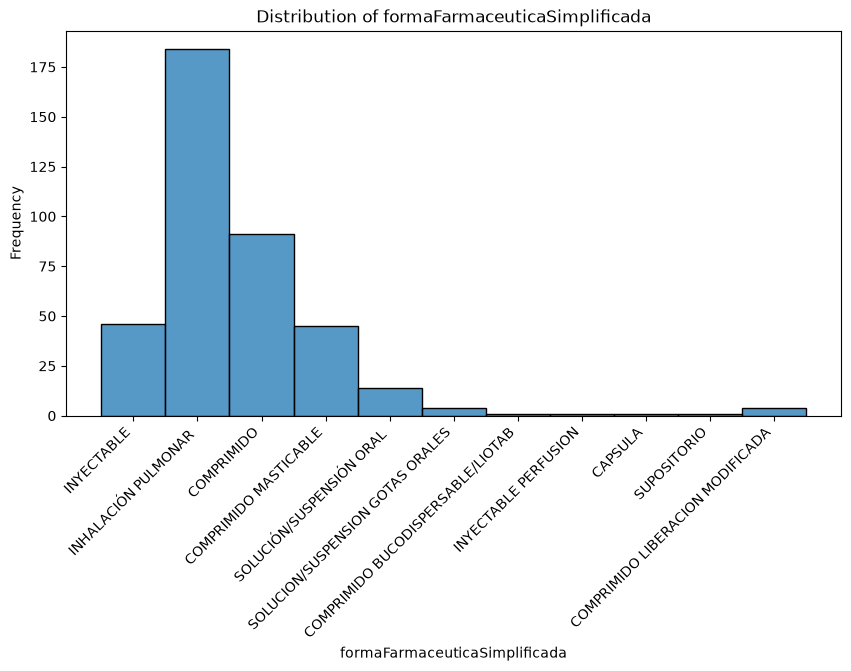

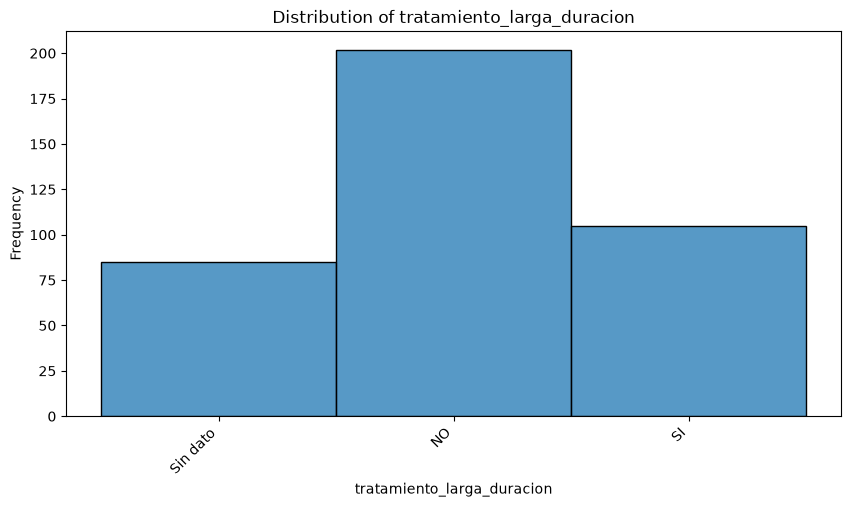

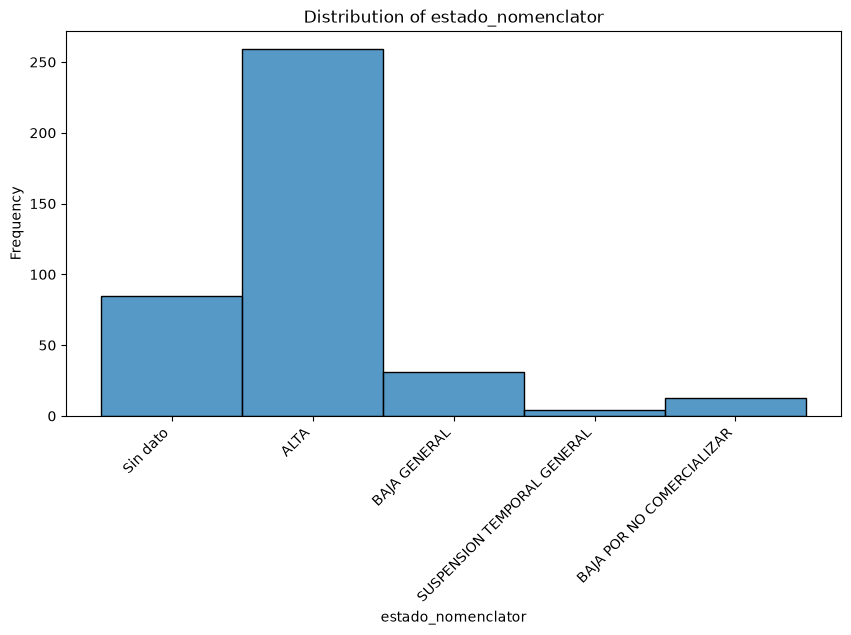

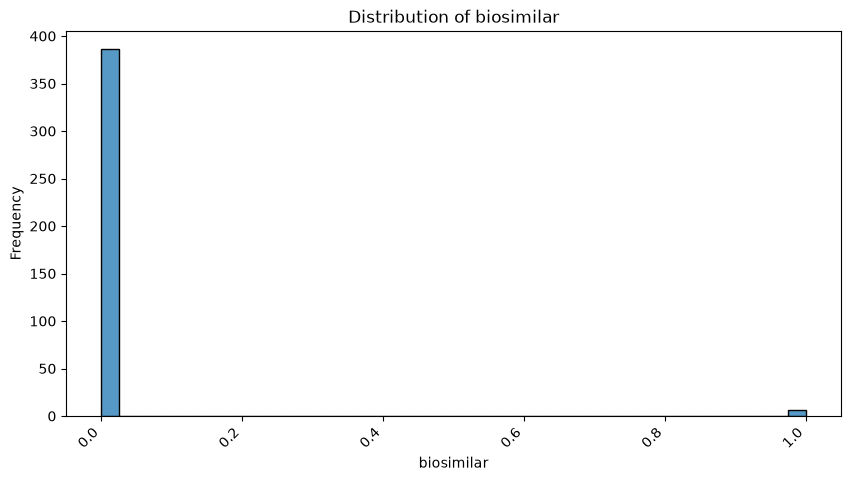

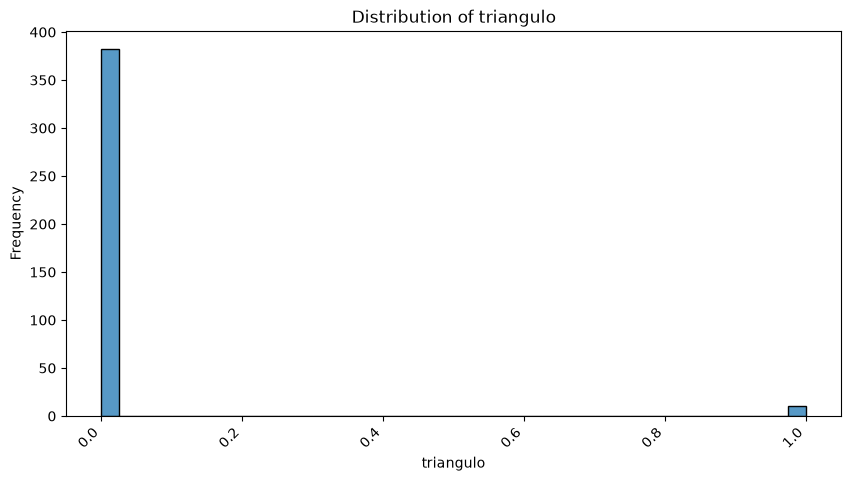

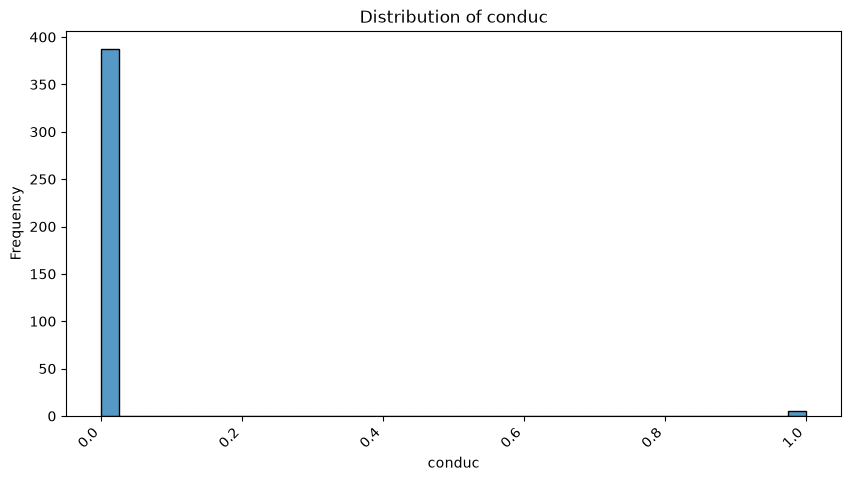

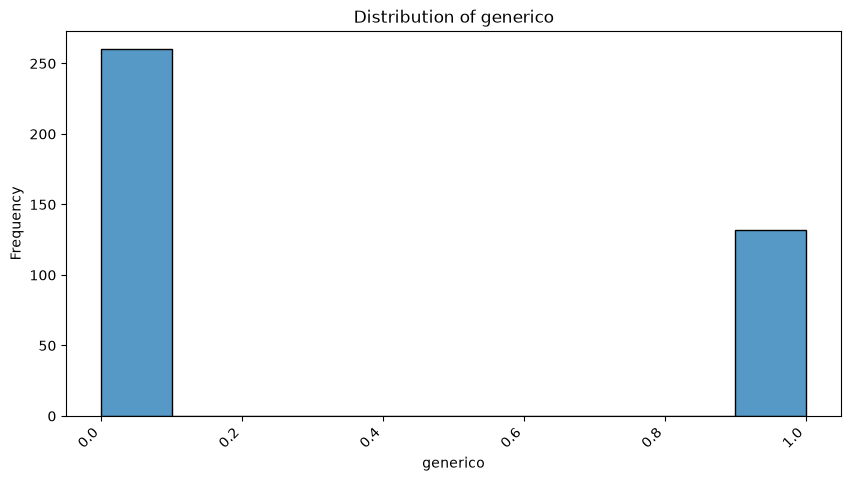

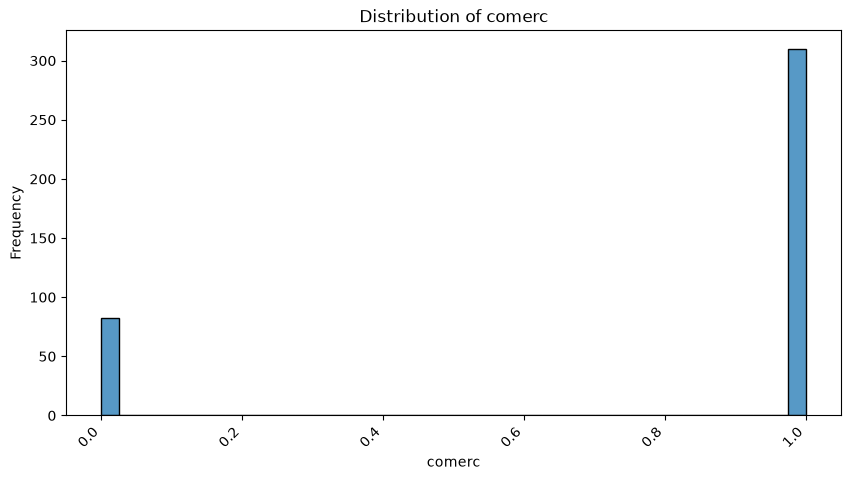

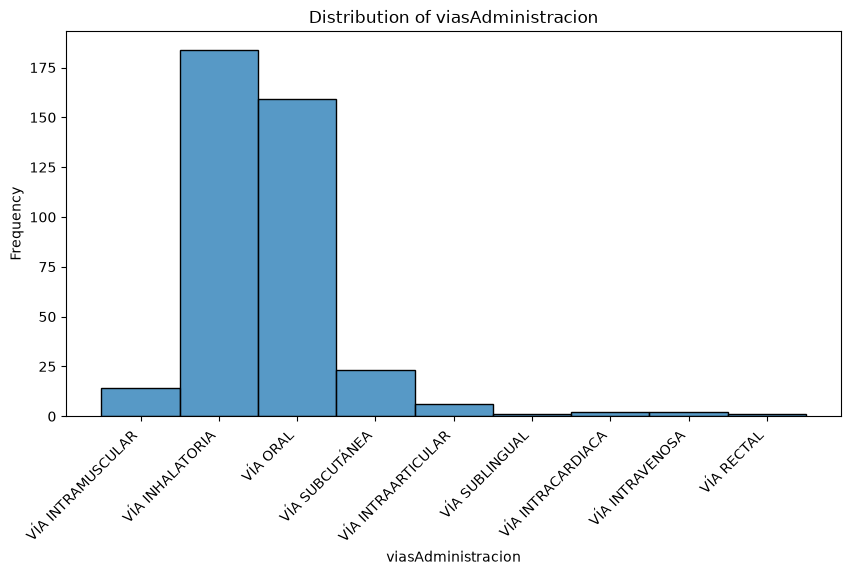

In [247]:
for column in categorical_columns:
    valores = df[column].fillna("Sin dato")
    plt.figure(figsize=(10, 5))
    sns.histplot(valores)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel('Frequency')
    plt.show()

Predomina la forma de inhalación pulmonar, seguida de los comprimidos.
Las vías de administración más frecuentes son la inhalatoria y la oral.

En tratamiento de larga duración hay más registros con NO que con SI, aunque una parte de los medicamentos no dispone de esta información.

El estado más frecuente en el Nomenclator es ALTA. También aparecen medicamentos de baja, suspendidos y registros sin información disponible.

Los indicadores de biosimilar, triángulo y conducción presentan pocos casos positivos. 

Los medicamentos no genéricos son más frecuentes que los genéricos.

La mayoría figura como comercializada.

La mayoria de medicamentos de administra vía inhalatoria y vía oral. El resto son mucho menos comunes.


## 7. Swarm plots de las variables numéricas

Ahora representamos las variables numéricas mediante swarm plots, que nos permiten observar la distribución de las variables de una manera más detallada

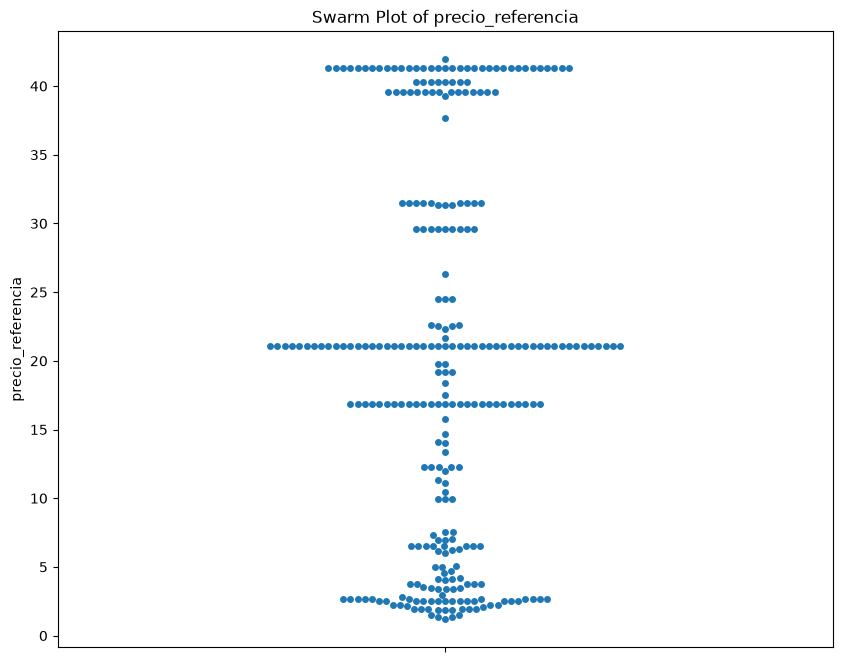

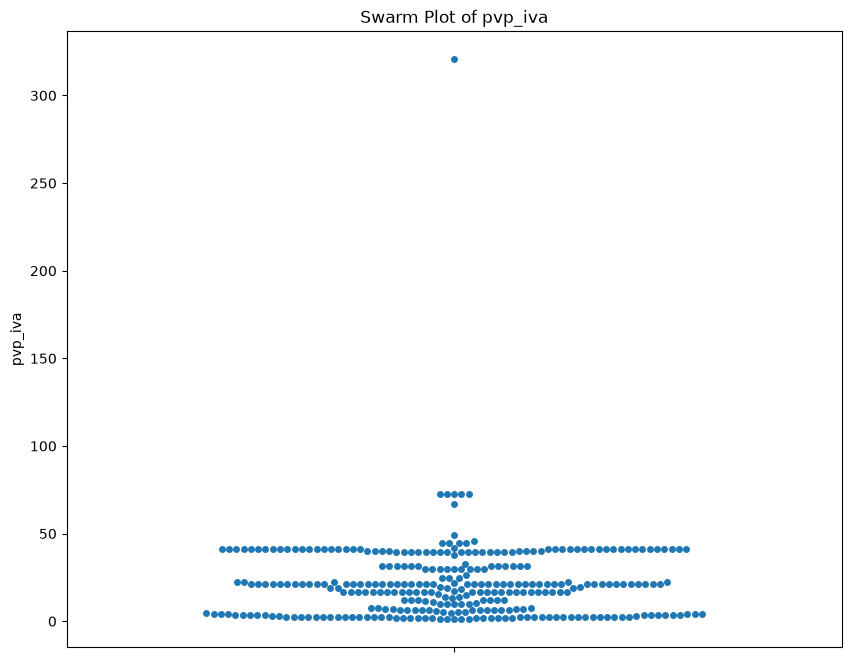

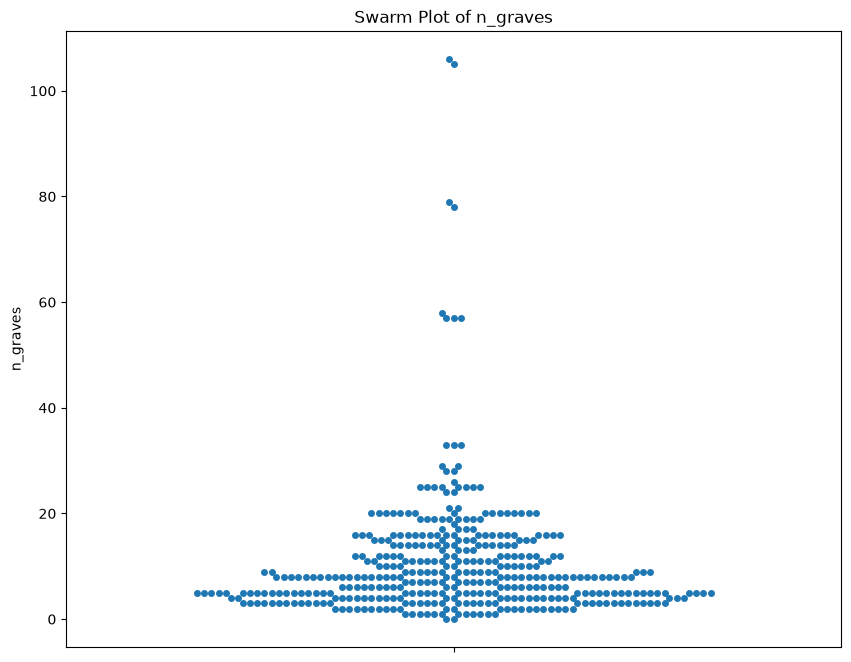

c:\Users\aleja\OneDrive\Escritorio\uni\ID\proyecto-asma\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 5.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


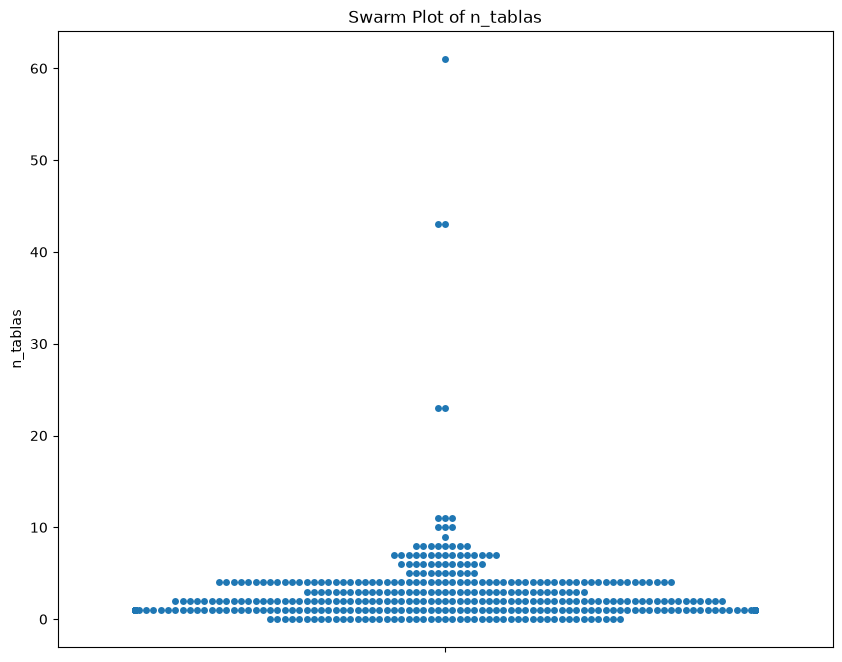

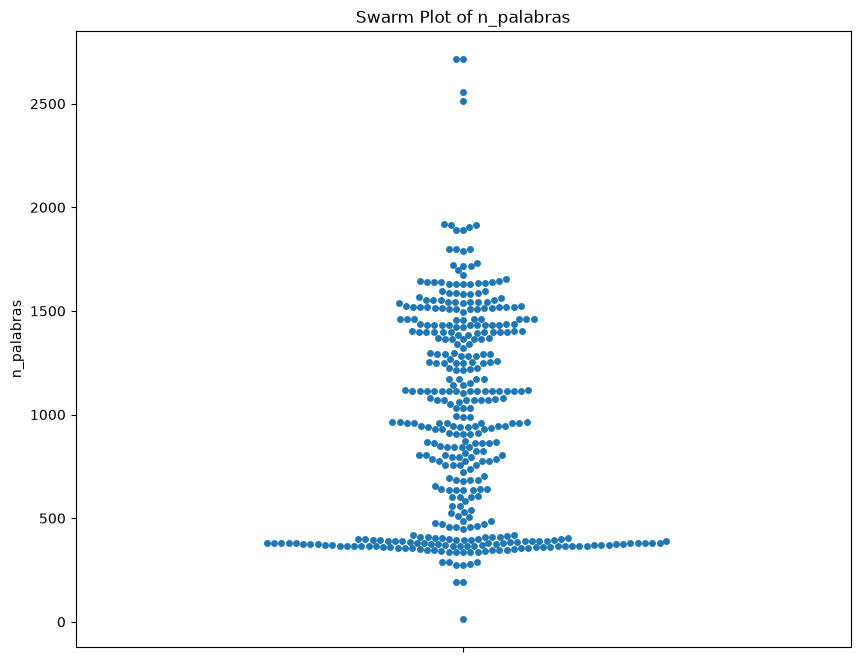

c:\Users\aleja\OneDrive\Escritorio\uni\ID\proyecto-asma\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 55.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


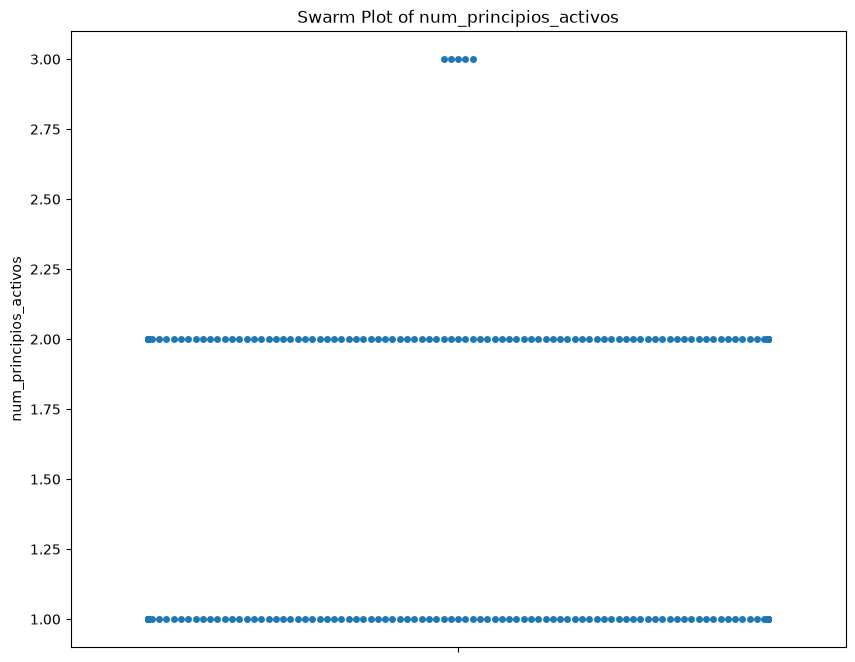

In [248]:
for column in numerical_columns:
    plt.figure(figsize=(10, 8))

    sns.swarmplot(y=column, data=df)

    plt.title(f'Swarm Plot of {column}')
    plt.ylabel(column)
    plt.show()

Las conslusiones que podemos sacar de los swarm plots son similares a las de los histogramas, aunque nos permiten ver mejor la distribución de los valores.

## 8. Relaciones entre variables 

Utilizamos una matriz de correlación para resumir las relaciones lineales entre las variables numéricas



In [249]:
df_drop = df.drop(columns=drop_columns)

<Axes: >

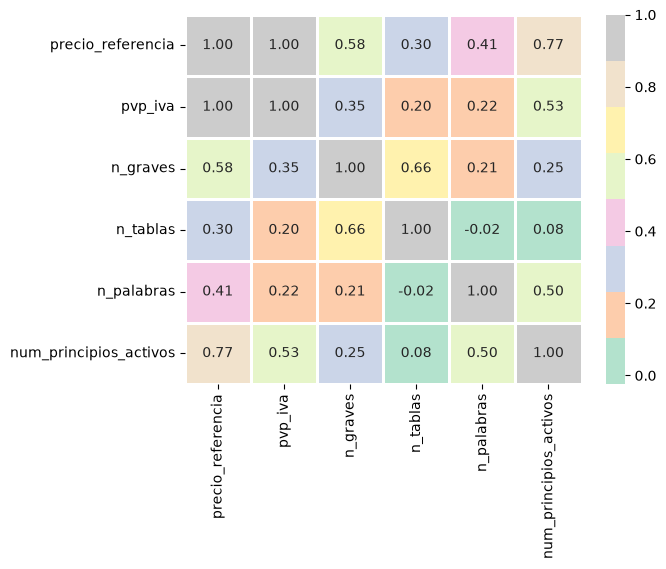

In [250]:


sns.heatmap(df_drop[numerical_columns].corr(), annot=True, fmt='.2f', cmap='Pastel2', linewidths=2)


El PVP y el precio de referencia presentan una correlación de 1,00. Seleccionamos el PVP, que tiene menos ausencias y contiene a todos los valores presentes en el precio de referencia.

El número de principios activos se asocia positivamente con el precio. La correlación es de 0,53 con el PVP.

El número de tablas y el recuento de graves presentan una asociación positiva de 0,66.

El número de principios activos también se relaciona con la extensiónde la sección analizada, con una correlación de 0,50.

El resto no tienen correlaciones significativas.

## 9. Dataset final para entrenamiento

Limpiamos nulos, quitamos columnas que no aportan información y nos quedamos con las columnas que nos interesan para el modelo de la HU5. Por último, guardamos el dataset limpio para el entrenamiento.

Como la revisión no ha identificado duplicados ni errores confirmados que justifiquen modificar los registros, conservamos los valores ausentes y los valores extremos no confirmados como errores.

La selección de variables y la imputación necesaria para el modelo se realizan en un dataset separado, y sobre el dataset original se añadirá la columna proveniente del clustering.

In [251]:
drop_columns.append("precio_referencia")
numerical_columns.remove("precio_referencia")

In [252]:
print(drop_columns)
print(numerical_columns)

['nregistro', 'nombre', 'cn', 'url_foto_materiales', 'url_html_ficha_tecnica', 'estado_rev', 'estado_aut', 'labtitular', 'pactivos', 'num_registros_atc', 'especial_control_medico', 'huerfano', 'receta', 'dosis', 'precio_referencia']
['pvp_iva', 'n_graves', 'n_tablas', 'n_palabras', 'num_principios_activos']


In [ ]:
df.drop(columns=drop_columns, inplace=True)


In [255]:
df["estado_nomenclator"] = df["estado_nomenclator"].fillna("Sin dato")

In [256]:
df["pvp_iva"] = df["pvp_iva"].fillna(df["pvp_iva"].mean())

In [257]:
df["tratamiento_larga_duracion"] = df["tratamiento_larga_duracion"].fillna("Sin dato")

In [ ]:
df.to_csv("../../datos_limpios.csv", index=False)

In [259]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   labcomercializador             392 non-null    str    
 1   formaFarmaceuticaSimplificada  392 non-null    str    
 2   viasAdministracion             392 non-null    str    
 3   comerc                         392 non-null    bool   
 4   generico                       392 non-null    bool   
 5   conduc                         392 non-null    bool   
 6   triangulo                      392 non-null    bool   
 7   biosimilar                     392 non-null    bool   
 8   num_principios_activos         392 non-null    int64  
 9   n_palabras                     392 non-null    int64  
 10  n_tablas                       392 non-null    int64  
 11  n_graves                       392 non-null    int64  
 12  estado_nomenclator             392 non-null    str    
 13  p